Within this dataset there is contained 31 years of data about 158 countries contained within 4898 rows and 19 columns with 15 of these columns being indicators. The remaining four columns are the countryiso3code, date, which region and if the Gini value has been imputed. The full list of indicators is contained within a list at the top of datasets.ipynb. All of the data has been collected for the time period of 1990-2020. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from indicator_titles import IndicatorTitles

MasterDataFrame = pd.read_csv('CleanedMasterDataFrame.csv')
DropColumn = list(MasterDataFrame.columns)
MasterDataFrame.drop(columns=DropColumn[0],inplace=True)

This depicts the number of entries we have per region of the world, the lower number of entries for regions such as South Asia and North America can be attributed to the lower number of members for these regions. This lower number of members for these regions result in there being more coverage of data for these regions. 

In [2]:
print(MasterDataFrame['Region'].value_counts()) 

Region
Europe & Central Asia                                1457
Sub-Saharan Africa                                   1302
Latin America & Caribbean                             806
East Asia & Pacific                                   589
Middle East, North Africa, Afghanistan & Pakistan     496
South Asia                                            186
North America                                          62
Name: count, dtype: int64


Looking at the number of actual values vs the number of imputed values

In [3]:
GroupedByRegion = [group for _,group in MasterDataFrame.groupby('Region')]
Bins = [1989,1999,2009,2021]
Labels = ['1990s','2000s','2010s']
MasterDataFrame['Decade'] = pd.cut(MasterDataFrame['date'],bins=Bins,labels=Labels)
GroupedByDecade = [group for _,group in MasterDataFrame.groupby('Decade')]

non_imputed_count = 0
imputed_count = 0

for iterator in GroupedByRegion:
    RegionName = iterator['Region'].iloc[0]
    NonImputedGiniDataframe = iterator.where((iterator['SI.POV.GINI'] > float(0)) & (iterator['IsOriginalValue']==True))

    RegionalGiniCount = NonImputedGiniDataframe['SI.POV.GINI'].count()
    RegionalGiniCountWithImputations = iterator['SI.POV.GINI'].count()
    
    print(f'{RegionName} : {RegionalGiniCount}')
    print(f'Imputed {RegionName} : {RegionalGiniCountWithImputations}')
    print('\n')
    non_imputed_count += RegionalGiniCount
    imputed_count += RegionalGiniCountWithImputations

East Asia & Pacific : 170
Imputed East Asia & Pacific : 327


Europe & Central Asia : 985
Imputed Europe & Central Asia : 1167


Latin America & Caribbean : 408
Imputed Latin America & Caribbean : 536


Middle East, North Africa, Afghanistan & Pakistan : 115
Imputed Middle East, North Africa, Afghanistan & Pakistan : 228


North America : 62
Imputed North America : 62


South Asia : 29
Imputed South Asia : 92


Sub-Saharan Africa : 196
Imputed Sub-Saharan Africa : 606




In [4]:
for iterator in GroupedByDecade:
    DecadeName = iterator['Decade'].iloc[0]
    NonImputedGiniDataframe = iterator.where((iterator['SI.POV.GINI'] > float(0)) & (iterator['IsOriginalValue']==True))

    DecadesGiniCount = NonImputedGiniDataframe['SI.POV.GINI'].count()
    DecadesGiniCountWithImputation = iterator['SI.POV.GINI'].count()
    
    print(f'{DecadeName} : {DecadesGiniCount}')
    print(f'Imputed {DecadeName} : {DecadesGiniCountWithImputation}')
    print('\n')

1990s : 378
Imputed 1990s : 694


2000s : 707
Imputed 2000s : 1123


2010s : 880
Imputed 2010s : 1201




In [5]:
GroupedByYears = [group for _,group in MasterDataFrame.groupby('date')]
NumberOfGiniByYear = pd.DataFrame({'Year': [] , 'Count' : []})
NumberOfGiniByYearWithImputes = pd.DataFrame({'Year' : [] , 'Count': []})
#got two dataframes with columns year 
for iterator in GroupedByYears:
    Year = iterator['date'].iloc[0]
    NoImputationsDataframe = iterator.where((iterator['SI.POV.GINI'] > float(0)) & (iterator['IsOriginalValue'] == True))
    #now have a dataframe without any imputations
    NoImputationsCount = NoImputationsDataframe['SI.POV.GINI'].count()
    WithImputationsCount = iterator['SI.POV.GINI'].count()

    NumberOfGiniByYear.loc[len(NumberOfGiniByYear)] = [Year,NoImputationsCount]
    NumberOfGiniByYearWithImputes.loc[len(NumberOfGiniByYearWithImputes)] = [Year,WithImputationsCount]


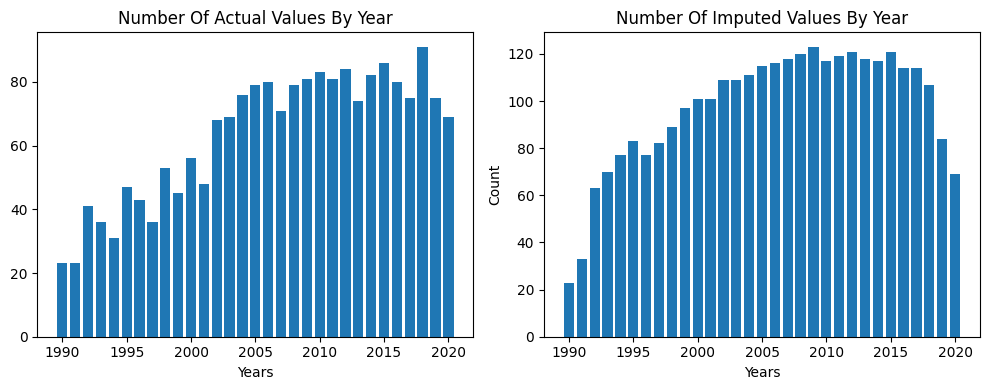

In [26]:
fig, axes = plt.subplots(nrows=1,ncols=2,figsize=(10,4))

axes[0].bar(NumberOfGiniByYear['Year'],
             NumberOfGiniByYear['Count'])
axes[1].bar(NumberOfGiniByYearWithImputes['Year'],
             NumberOfGiniByYearWithImputes['Count'])

axes[0].set_title("Number Of Actual Values By Year",loc="center")
axes[1].set_title("Number Of Imputed Values By Year",loc="center")

axes[0].set_xlabel("Years")
axes[1].set_xlabel("Years")

axes[1].set_ylabel("Count")
axes[1].set_ylabel("Count")

fig.tight_layout()

plt.show()


In [7]:
#could make a copy and then drop all the columns apart from the ones i need to count
CopyDataFrame = MasterDataFrame.copy(deep=True)
ColumnsToDropFrom = ['countryiso3code','date','SI.POV.GINI','IsOriginalValue','Decade','Region']
CopyDataFrame = CopyDataFrame.drop(ColumnsToDropFrom,axis=1)
CopyColumnNames = list(CopyDataFrame.columns)

PercentageOfMissingValues = pd.DataFrame({'Indicator':[],'Percentage of Missing Values':[]})
NumberEntriesPerColumn = len(CopyDataFrame)

for iterator in CopyColumnNames:
    NumberOfValidEntries = CopyDataFrame[iterator].count()
    PercentageOfEntriesMissing = 100 - ((NumberOfValidEntries / NumberEntriesPerColumn) * 100)
    PercentageOfMissingValues.loc[len(PercentageOfMissingValues)] = [iterator,PercentageOfEntriesMissing]
    
print(PercentageOfMissingValues)

                    Indicator  Percentage of Missing Values
0                 SI.POV.DDAY                      0.000000
1              SI.DST.10TH.10                      0.000000
2              SI.DST.FRST.20                      0.000000
3              NE.TRD.GNFS.ZS                      5.063291
4        BX.KLT.DINV.WD.GD.ZS                      0.000000
5              NY.GDP.PCAP.KD                      0.000000
6           NY.GDP.MKTP.KD.ZG                      0.000000
7           NE.CON.PRVT.PC.KD                      7.594937
8              SL.UEM.TOTL.ZS                      0.632911
9              SL.UEM.1524.ZS                      0.632911
10             SL.TLF.CACT.ZS                      0.632911
11             FP.CPI.TOTL.ZG                      0.000000
12          GC.TAX.TOTL.GD.ZS                     12.025316
13          GC.XPN.TOTL.GD.ZS                     11.392405
14  GiniSpikeWithinThreeYears                     43.140057


In [8]:
GroupedByCountry = [group for _, group in MasterDataFrame.groupby('countryiso3code')]

for i, countryiterator in enumerate(GroupedByCountry):
    GiniColumn = countryiterator['SI.POV.GINI']
    
    spike_results_list = []
    
    for iterator in range(0, len(GiniColumn)):
        CurrentGiniValue = GiniColumn.iloc[iterator]

        if pd.isna(CurrentGiniValue) == True:
            spike_results_list.append(pd.NA)  
            continue

        try:
            NextGiniValue = GiniColumn.iloc[iterator + 1]
        except IndexError:
            NextGiniValue = pd.NA

        try:
            NextSecondGiniValue = GiniColumn.iloc[iterator + 2]
        except IndexError:
            NextSecondGiniValue = pd.NA

        try:
            NextThirdGiniValue = GiniColumn.iloc[iterator + 3]
        except IndexError:
            NextThirdGiniValue = pd.NA
        
        FutureGiniConditions = [pd.isna(NextGiniValue), pd.isna(NextSecondGiniValue), pd.isna(NextThirdGiniValue)]
        
        if all(FutureGiniConditions):
            spike_results_list.append(pd.NA) 
            continue
        
        if pd.isna(NextGiniValue) == True:
            NextGiniValue = -999
        if pd.isna(NextSecondGiniValue) == True:
            NextSecondGiniValue = -999
        if pd.isna(NextThirdGiniValue) == True:
            NextThirdGiniValue = -999
        
        GiniSpikeConditions = [
            NextGiniValue - CurrentGiniValue > 1.8,
            NextSecondGiniValue - CurrentGiniValue > 1.8,
            NextThirdGiniValue - CurrentGiniValue > 1.8
        ]
            
        if any(GiniSpikeConditions):
            spike_results_list.append(1)  
        else:
            spike_results_list.append(0)  

    updated_country = countryiterator.copy()
    updated_country['GiniSpikeWithinThreeYears'] = spike_results_list
    
    GroupedByCountry[i] = updated_country

MasterDataFrame = pd.concat(GroupedByCountry, axis=0)

In [9]:
NumberOfSpikesandNonSpikes = list(MasterDataFrame['GiniSpikeWithinThreeYears'].value_counts())
RatioBetweenSpikesAndNonSpikes = NumberOfSpikesandNonSpikes[0] / NumberOfSpikesandNonSpikes[1]
DifferentWayOfLookingAtRatio = (NumberOfSpikesandNonSpikes[1] / (NumberOfSpikesandNonSpikes[0] + NumberOfSpikesandNonSpikes[1])) * 100
print(f'Spikes represent around {DifferentWayOfLookingAtRatio:.2f} % of all labelled rows')
print(f'For every 1 spike there is : {RatioBetweenSpikesAndNonSpikes:.3f} number of non spikes')

Spikes represent around 24.56 % of all labelled rows
For every 1 spike there is : 3.072 number of non spikes


<Axes: xlabel='Region'>

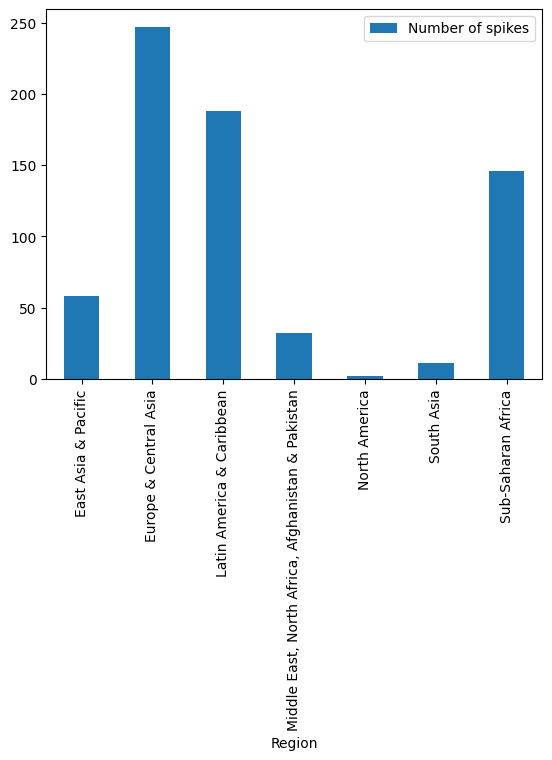

In [10]:
#need to create new GroupedByRegion since it doesn't have the spike column
GroupedByRegionWithGiniSpikes = [group for _,group in MasterDataFrame.groupby('Region')]
BarGraphDataframe = pd.DataFrame({'Region':[],'Number of spikes':[]})

for iterator in GroupedByRegionWithGiniSpikes:
    RegionName = iterator['Region'].iloc[0]
    SpikesandNonSpikesByRegion = iterator['GiniSpikeWithinThreeYears'].value_counts()
    BarGraphDataframe.loc[len(BarGraphDataframe)] = [RegionName,SpikesandNonSpikesByRegion[1]]

BarGraphDataframe.plot.bar(x='Region',y='Number of spikes')

In [27]:
GroupedByDecadeWithGiniSpikes = [group for _,group in MasterDataFrame.groupby('Decade')]
BarGraphDataframe = pd.DataFrame({'Decade':[],'Number of spikes':[]})
for iterator in GroupedByDecadeWithGiniSpikes:
    DecadeName = iterator['Decade'].iloc[0]
    SpikesandNonSpikesByDecade = iterator['GiniSpikeWithinThreeYears'].value_counts()
    BarGraphDataframe.loc[len(BarGraphDataframe)] = [DecadeName,SpikesandNonSpikesByDecade[1]]

Text(0, 0.5, 'Count')

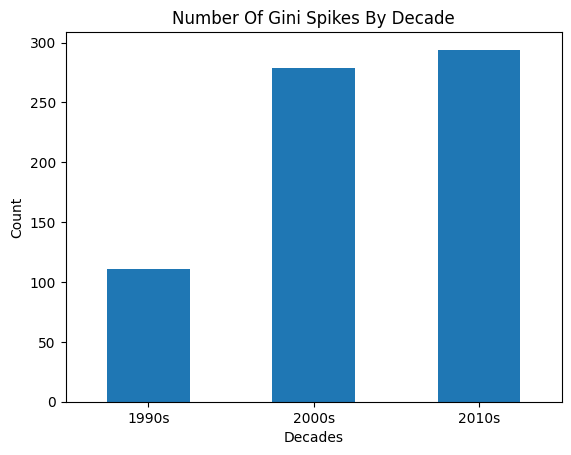

In [33]:
ax = BarGraphDataframe.plot.bar(x='Decade',
                                y='Number of spikes',
                                rot=0,
                                legend = False)

ax.set_title('Number Of Gini Spikes By Decade')
ax.set_xlabel('Decades')
ax.set_ylabel('Count')

In [12]:
AllSpikeDataframe = MasterDataFrame.where((MasterDataFrame['IsOriginalValue']==True) & (MasterDataFrame['GiniSpikeWithinThreeYears']==1))
AllSpikeDataframe = AllSpikeDataframe.dropna(axis=0,how='all')
LocationOfSpikeEntries = list(AllSpikeDataframe.index)


In [13]:
AllSpikeDataframe = MasterDataFrame.where(
    (MasterDataFrame['IsOriginalValue'] == True) &
    (MasterDataFrame['GiniSpikeWithinThreeYears'] == 1)
).dropna(axis=0, how='all')

AllNonSpikeDataframe = MasterDataFrame.where(
    (MasterDataFrame['IsOriginalValue'] == True) &
    (MasterDataFrame['GiniSpikeWithinThreeYears'] == 0)
).dropna(axis=0, how='all')

SpikeEvents    = list(zip(AllSpikeDataframe['countryiso3code'],    AllSpikeDataframe['date'].astype(int)))
NonSpikeEvents = list(zip(AllNonSpikeDataframe['countryiso3code'], AllNonSpikeDataframe['date'].astype(int)))

print(f"Total spike events:     {len(SpikeEvents)}")
print(f"Total non-spike events: {len(NonSpikeEvents)}")


Total spike events:     493
Total non-spike events: 1314


In [14]:
WINDOW = range(-5, 4)  # -5, -4, -3, -2, -1, 0, +1, +2, +3

def CollectGiniWindow(CountryCode, SpikeYear, Dataframe):
    CountryData = Dataframe[Dataframe['countryiso3code'] == CountryCode].copy()
    CountryData = CountryData.set_index('date')

    WindowValues = {}
    for Offset in WINDOW:
        TargetYear = SpikeYear + Offset
        if TargetYear in CountryData.index:
            WindowValues[Offset] = CountryData.loc[TargetYear, 'SI.POV.GINI']
        else:
            WindowValues[Offset] = pd.NA

    return WindowValues


In [15]:
SpikeWindows    = [CollectGiniWindow(Country, Year, MasterDataFrame) for Country, Year in SpikeEvents]
NonSpikeWindows = [CollectGiniWindow(Country, Year, MasterDataFrame) for Country, Year in NonSpikeEvents]

SpikeTrajectory    = pd.DataFrame(SpikeWindows,    columns=WINDOW).mean(skipna=True)
NonSpikeTrajectory = pd.DataFrame(NonSpikeWindows, columns=WINDOW).mean(skipna=True)

print("Average Gini - Spike trajectory:")
print(SpikeTrajectory.round(2).to_string())
print()
print("Average Gini - Stable trajectory:")
print(NonSpikeTrajectory.round(2).to_string())

Average Gini - Spike trajectory:
-5    41.14
-4    41.08
-3    41.22
-2    40.84
-1    39.91
0     38.55
1     38.61
2     38.68
3     38.71

Average Gini - Stable trajectory:
-5    36.23
-4    36.12
-3    36.36
-2    36.41
-1    36.59
0     36.92
1     36.48
2     36.45
3     36.49


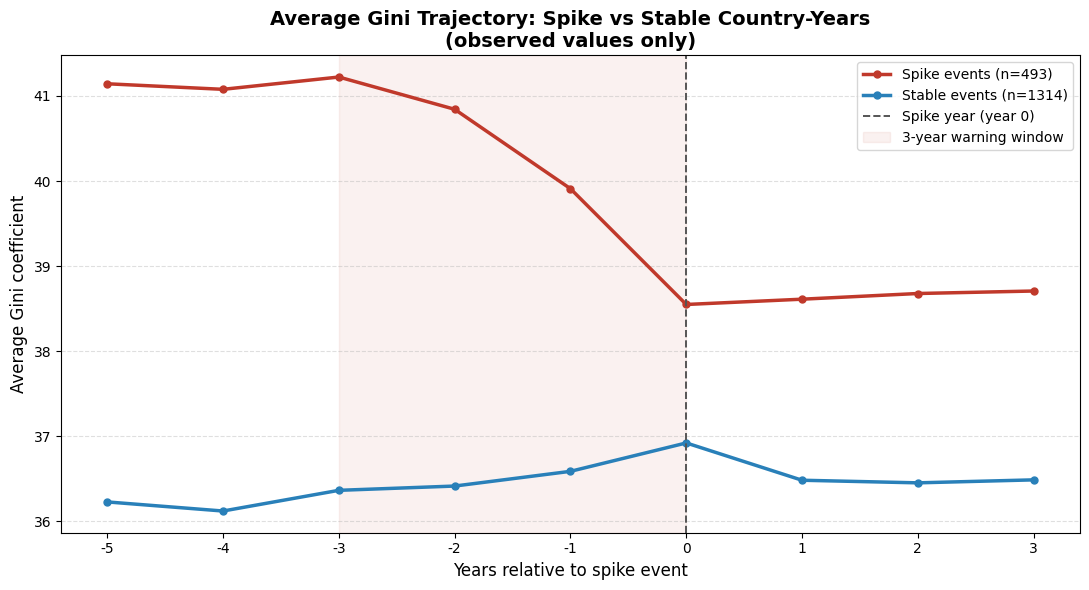

In [16]:
Fig, Ax = plt.subplots(figsize=(11, 6))

Ax.plot(
    SpikeTrajectory.index,
    SpikeTrajectory.values,
    color='#C0392B',
    linewidth=2.5,
    marker='o',
    markersize=5,
    label=f'Spike events (n={len(SpikeWindows)})'
)

Ax.plot(
    NonSpikeTrajectory.index,
    NonSpikeTrajectory.values,
    color='#2980B9',
    linewidth=2.5,
    marker='o',
    markersize=5,
    label=f'Stable events (n={len(NonSpikeWindows)})'
)

Ax.axvline(
    x=0,
    color='#555555',
    linestyle='--',
    linewidth=1.4,
    label='Spike year (year 0)'
)

Ax.axvspan(
    -3, 0,
    alpha=0.07,
    color='#C0392B',
    label='3-year warning window'
)

Ax.set_xlabel('Years relative to spike event', fontsize=12)
Ax.set_ylabel('Average Gini coefficient', fontsize=12)
Ax.set_title(
    'Average Gini Trajectory: Spike vs Stable Country-Years\n(observed values only)',
    fontsize=14,
    fontweight='bold'
)
Ax.set_xticks(list(WINDOW))
Ax.set_xticklabels([str(x) for x in WINDOW])
Ax.legend(fontsize=10)
Ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('gini_event_study.png', dpi=150, bbox_inches='tight')
plt.show()


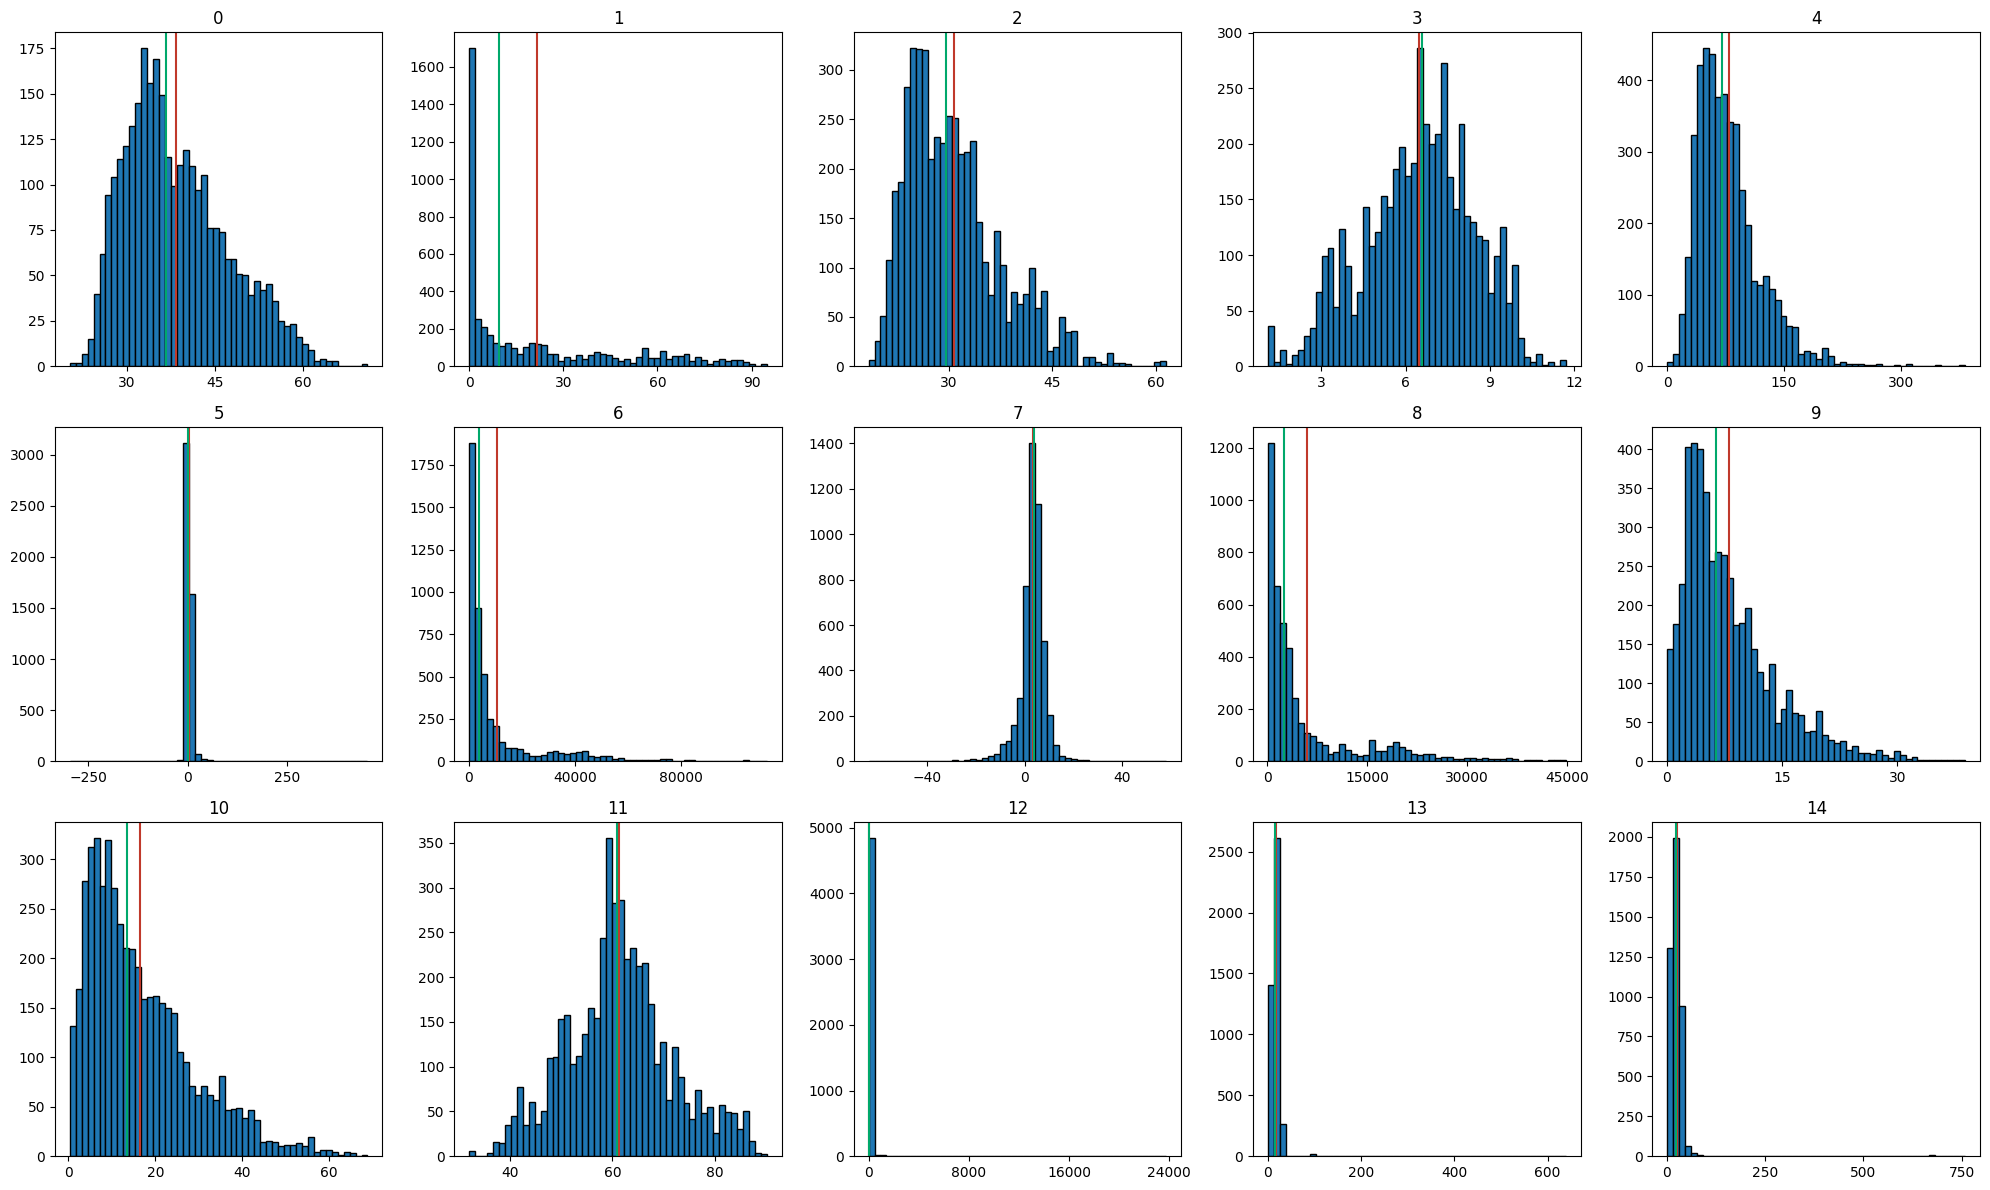

                                           Indicators
0                                          Gini Index
1   Poverty Headcount Ratio at $2.15 a Day (2017 PPP)
2                    Income Share Held by Highest 10%
3                     Income Share Held by Lowest 20%
4                                    Trade (% of GDP)
5   Foreign Direct Investment, Net Inflows (% of GDP)
6                    GDP Per Capita (Constant Prices)
7                               GDP Growth (Annual %)
8   Household Consumption Expenditure Per Capita G...
9        Unemployment, Total (% of Total Labor Force)
10  Youth Unemployment, Total (% of Labor Force Ag...
11  Labor Force Participation Rate, Total (% of Po...
12              Inflation, Consumer Prices (Annual %)
13                             Tax Revenue (% of GDP)
14                      Government Expense (% of GDP)


In [17]:
ListOfColumns = list(MasterDataFrame.columns)
NonIndicatorColumns = ['countryiso3code','date','IsOriginalValue','Region','Decade','GiniSpikeWithinThreeYears']
ListOfColumns = [col for col in ListOfColumns if col not in NonIndicatorColumns]

fig, axes = plt.subplots(nrows=3,ncols=5,figsize=(20,12)) #in order to iterate through this need to call Axes
axes = axes.reshape(-1) #flattening the 2d array to make iteration easier

for ax in range(len(axes)):
    Column = MasterDataFrame[ListOfColumns[ax]]
    ColumnMean = Column.mean()
    ColumnMedian = Column.median()

    axes[ax].axvline(
        x = ColumnMean,
        color = '#C0392B'
    )

    axes[ax].axvline(
        x = ColumnMedian,
        color = '#00A86B'
    )

    axes[ax].xaxis.set_major_locator(plt.MaxNLocator(4))

    axes[ax].hist(Column,bins=50,edgecolor='black')
    axes[ax].set_title(ax,fontsize=12)
    
plt.tight_layout()
plt.savefig('indicator_histograms.png',dpi=150,bbox_inches='tight')
plt.show()
print(pd.DataFrame(IndicatorTitles).drop(columns='numbers'))

In [18]:
if 'SI.POV.GINI' not in CopyDataFrame.columns:
        CopyDataFrame = pd.merge(MasterDataFrame['SI.POV.GINI'],
                         CopyDataFrame,
                         left_index=True, right_index=True)

AllIndicatorsSkew = CopyDataFrame.skew()

In [19]:
Quartile1 = CopyDataFrame.quantile(0.25,axis=0,interpolation='midpoint')
Quartile3 = CopyDataFrame.quantile(0.75,axis=0,interpolation='midpoint')
QuartileDataFrame = pd.merge(Quartile1,Quartile3,left_index=True,right_index=True)

ColumnWiseMedian = CopyDataFrame.median(axis=0)
ColumnWiseMedian.name = 'Median'

QuartileDataFrame = pd.merge(QuartileDataFrame,ColumnWiseMedian,left_index=True,right_index=True)
QuartileDataFrameRowNames = list(QuartileDataFrame.index)

QuartileDataFrame['IQR'] = pd.NA #filled with NA for the moment

for i in QuartileDataFrameRowNames:
    Q1andQ3 = QuartileDataFrame.loc[i]
    TempQuartile1 = Q1andQ3.iloc[0]
    TempQuartile3 = Q1andQ3.iloc[1]
    IQR = TempQuartile3 - TempQuartile1
    QuartileDataFrame.loc[i,'IQR'] = IQR

In [20]:
OutlierSummaryDataFrame = pd.DataFrame({'countryiso3code':[],
                                        'date':[],
                                        'Indicators':[]})

for i in ListOfColumns:
    TempMedianValue = QuartileDataFrame.loc[i,'Median'] #should be the median value of indicator
    TempIQRValue = QuartileDataFrame.loc[i,'IQR'] #should be the IQR value of indicator
    TempIndiatorSeriesHolder = MasterDataFrame[i] #should be the series of indicator i

    TripledIQRValue = TempIQRValue * 3

    LeftBound = TempMedianValue - TripledIQRValue
    RightBound = TempMedianValue + TripledIQRValue

    OutlierCheck = ((LeftBound > TempIndiatorSeriesHolder) |
                    (TempIndiatorSeriesHolder > RightBound))

    OutlierIndexes = [i for i, x in enumerate(list(OutlierCheck)) if x == True]

    for j in OutlierIndexes:
        OutlierRowCountryCode = MasterDataFrame.loc[j,'countryiso3code']
        OutlierRowDate = MasterDataFrame.loc[j,'date']
        
        OutlierSummaryDataFrame.loc[len(OutlierSummaryDataFrame)] = [OutlierRowCountryCode,OutlierRowDate,i]


In [21]:
MasterDataFrame.to_csv('CleanedMasterDataFrame.csv')
OutlierSummaryDataFrame.to_csv('OutlierDataFrame.csv')